In [2]:
# Importação de bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.cm as cm
from scipy import stats
from scipy.stats import norm, poisson, t
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
import warnings
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv('/kaggle/input/tp2-data-exploration/bank-full.csv', sep=';') 
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [5]:
# Remover espaços em branco das colunas
df.columns = df.columns.str.strip()

# Verificar valores "unknown" e convertê-los para NaN
for col in df.columns:
    if df[col].dtype == 'object':
        print(f"{col}: {df[col].value_counts().get('unknown', 0)} 'unknown' encontrados")
df.replace('unknown', np.nan, inplace=True)

# Preencher valores ausentes
for col in df.columns:
    if df[col].dtype == 'object':
        df[col].fillna(df[col].mode()[0], inplace=True)
    else:
        df[col].fillna(df[col].mean(), inplace=True)

# Atualizar dataset limpo
df_clean = df.copy()
print("Dimensão final do dataset limpo:", df_clean.shape)

job: 288 'unknown' encontrados
marital: 0 'unknown' encontrados
education: 1857 'unknown' encontrados
default: 0 'unknown' encontrados
housing: 0 'unknown' encontrados
loan: 0 'unknown' encontrados
contact: 13020 'unknown' encontrados
month: 0 'unknown' encontrados
poutcome: 36959 'unknown' encontrados
y: 0 'unknown' encontrados
Dimensão final do dataset limpo: (45211, 17)


In [6]:
# Identificação manual 
atributos_continuos = ['age', 'balance', 'duration', 'campaign', 'pdays', 'previous']
atributos_discretos = ['day']

df_clean[atributos_continuos] = df_clean[atributos_continuos].apply(pd.to_numeric)

# Estatísticas descritivas básicas
df_clean[atributos_continuos + atributos_discretos].describe().T

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


In [7]:
# Número de elementos da amostra
n = df_clean.shape[0]
print(f"Número de elementos da amostra: {n}")

Número de elementos da amostra: 45211


In [7]:
# Minimo de cada atributo contínuo e discreto
df_clean[atributos_continuos + atributos_discretos].min()

age           18
balance    -8019
duration       0
campaign       1
pdays         -1
previous       0
day            1
dtype: int64

In [8]:
# Máximo de cada atributo contínuo e discreto
df_clean[atributos_continuos + atributos_discretos].max()

age             95
balance     102127
duration      4918
campaign        63
pdays          871
previous       275
day             31
dtype: int64

In [9]:
# Moda de cada atributo contínuo e discreto
for col in atributos_continuos + atributos_discretos:
    print(f"{col}: Moda = {df_clean[col].mode().values}")

age: Moda = [32]
balance: Moda = [0]
duration: Moda = [124]
campaign: Moda = [1]
pdays: Moda = [-1]
previous: Moda = [0]
day: Moda = [20]


In [10]:
# Mediana de cada atributo contínuo e discreto
df_clean[atributos_continuos + atributos_discretos].median()

age          39.0
balance     448.0
duration    180.0
campaign      2.0
pdays        -1.0
previous      0.0
day          16.0
dtype: float64

In [12]:
# Média de cada atributo contínuo e discreto
df_clean[atributos_continuos + atributos_discretos].mean()

age           40.936210
balance     1362.272058
duration     258.163080
campaign       2.763841
pdays         40.197828
previous       0.580323
day           15.806419
dtype: float64

In [13]:
# 1º e 3º quartis de cada atributo contínuo e discreto
quartis = df_clean[atributos_continuos + atributos_discretos].quantile([0.25, 0.75])
quartis

,age,balance,duration,campaign,pdays,previous,day
0.25,33.0,72.0,103.0,1.0,-1.0,0.0,8.0
0.75,48.0,1428.0,319.0,3.0,-1.0,0.0,21.0


In [14]:
# Desvio padrão de cada atributo contínuo e discreto
df_clean[atributos_continuos + atributos_discretos].std()

age           10.618762
balance     3044.765829
duration     257.527812
campaign       3.098021
pdays        100.128746
previous       2.303441
day            8.322476
dtype: float64

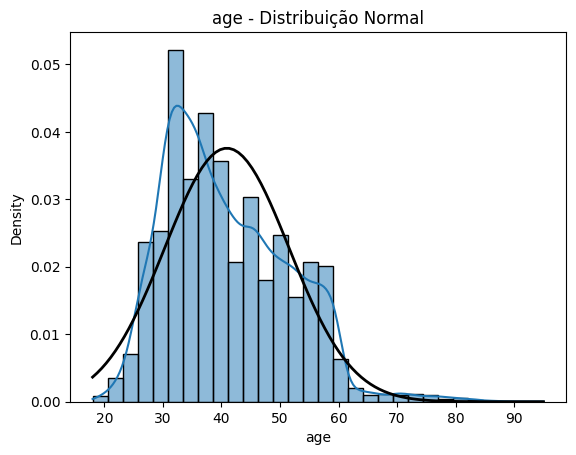

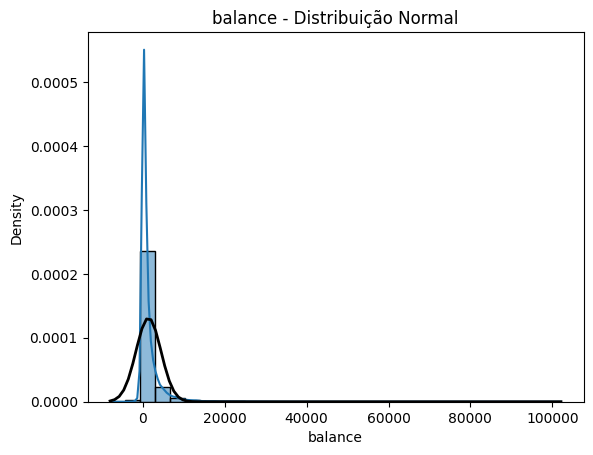

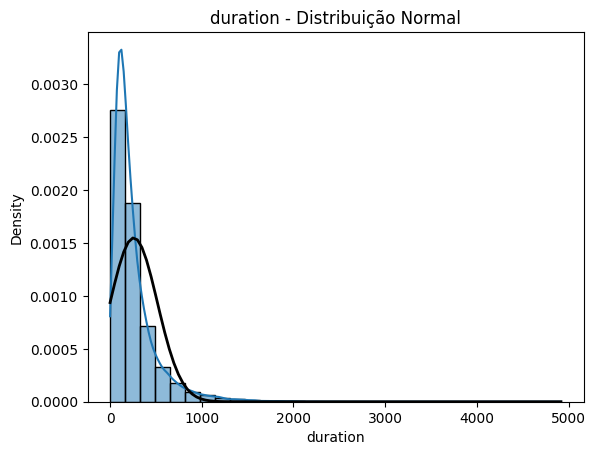

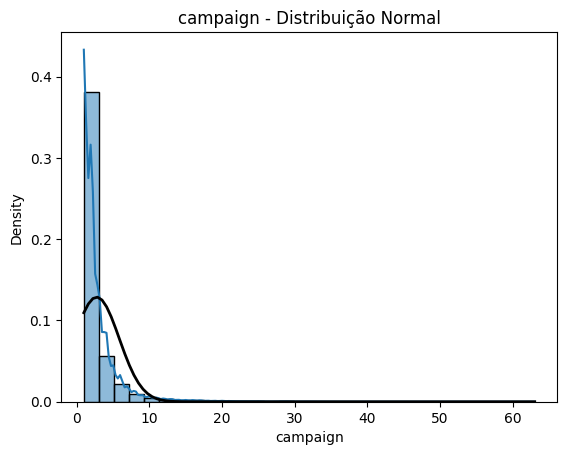

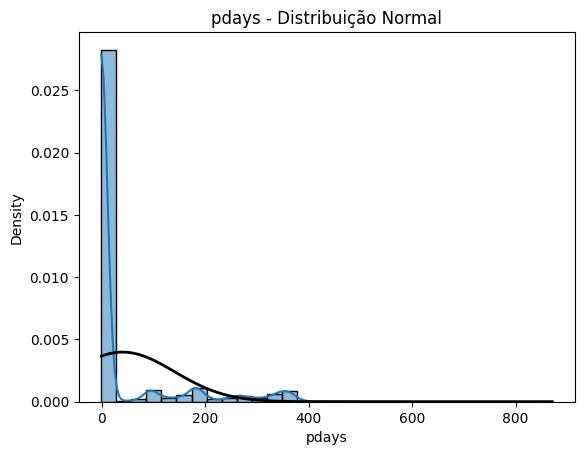

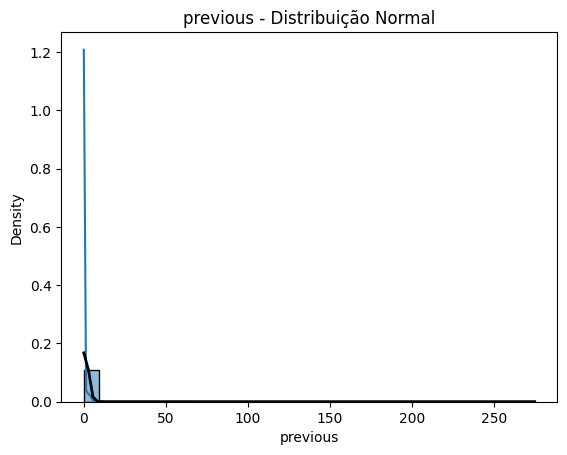

In [15]:
# Distribuição normal
for col in atributos_continuos:
    sns.histplot(df_clean[col], kde=Tue, stat='density', bins=30)
    mu, std = df_clean[col].mean(), df_clean[col].std()
    x = np.linspace(df_clean[col].min(), df_clean[col].max(), 100)
    p = stats.norm.pdf(x, mu, std)
    plt.plot(x, p, 'k', linewidth=2)
    plt.title(f'{col} - Distribuição Normal')
    plt.show()

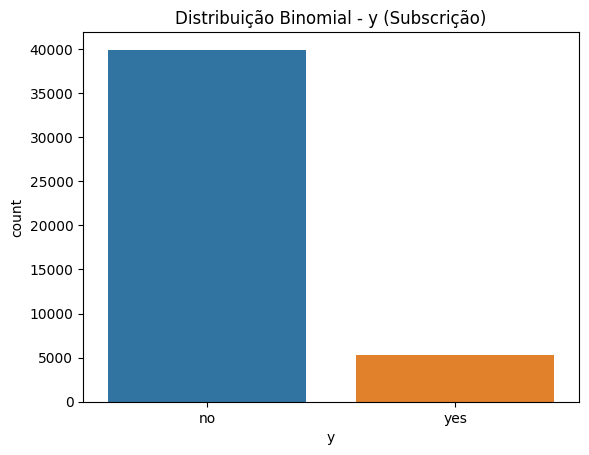

In [16]:
# Distribuição binomial
sns.countplot(x='y', data=df_clean)
plt.title("Distribuição Binomial - y (Subscrição)")
plt.show()

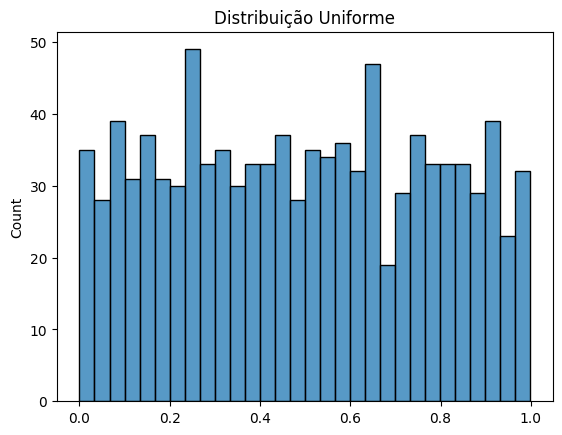

In [18]:
# Distribuição Uniforme
uniforme = np.random.uniform(low=0, high=1, size=1000)
sns.histplot(uniforme, bins=30, kde=False)
plt.title("Distribuição Uniforme")
plt.show()

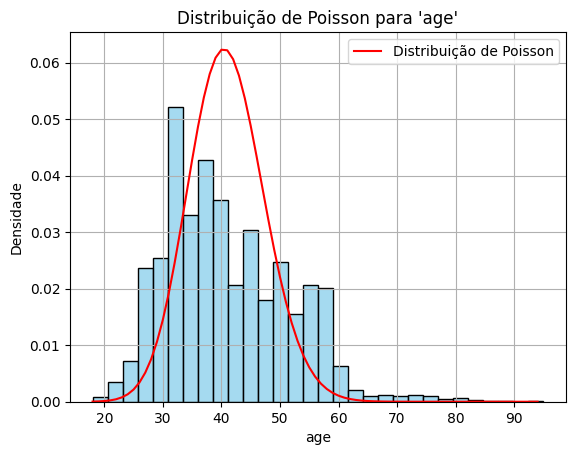

In [9]:
# Distribuição Poisson
col = 'age'
sns.histplot(df_clean[col], bins=30, kde=False, stat='density', color='skyblue')
mu = df_clean[col].mean()
x = np.arange(df_clean[col].min(), df_clean[col].max())
p = poisson.pmf(x, mu)
plt.plot(x, p, 'r', label='Distribuição de Poisson')
plt.title(f"Distribuição de Poisson para '{col}'")
plt.xlabel(col)
plt.ylabel('Densidade')
plt.legend()
plt.grid(True)
plt.show()

Intervalo de confiança 95% para a média de 'balance': [1334.21, 1390.34]


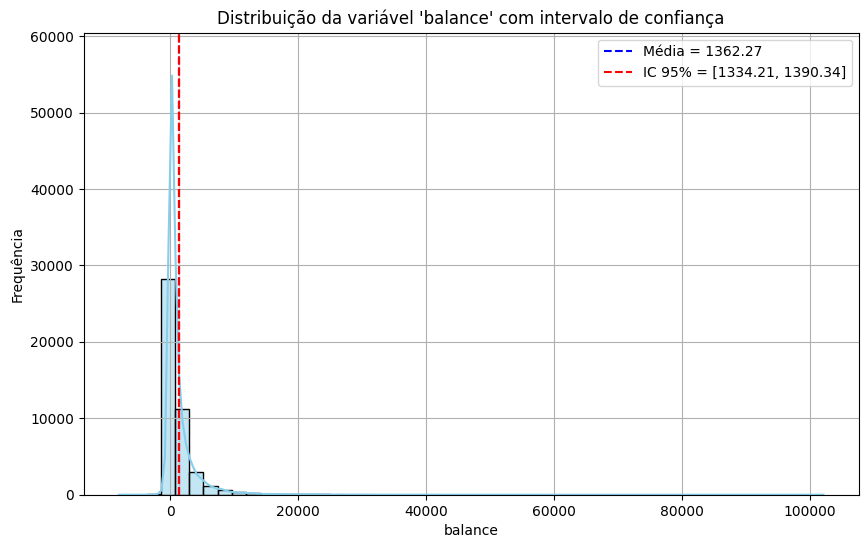

In [23]:
# T-Student
col = 'balance'
mean = df_clean[col].mean()
std = df_clean[col].std()
n = df_clean[col].count()
conf = 0.95
t_crit = t.ppf((1 + conf) / 2, df=n-1)
margin = t_crit * (std / np.sqrt(n))
lower = mean - margin
upper = mean + margin
print(f"Intervalo de confiança 95% para a média de '{col}': [{mean - margin:.2f}, {mean + margin:.2f}]")

plt.figure(figsize=(10, 6))
sns.histplot(df_clean[col], kde=True, color='skyblue', bins=50)
plt.axvline(mean, color='blue', linestyle='--', label=f'Média = {mean:.2f}')
plt.axvline(lower, color='red', linestyle='--', label=f'IC 95% = [{lower:.2f}, {upper:.2f}]')
plt.axvline(upper, color='red', linestyle='--')
plt.fill_betweenx([0, plt.gca().get_ylim()[1]], lower, upper, color='red', alpha=0.2)
plt.title(f"Distribuição da variável '{col}' com intervalo de confiança")
plt.xlabel(col)
plt.ylabel('Frequência')
plt.legend()
plt.grid(True)
plt.show()

In [21]:
# Intervalo de confiança
def intervalo_conf(col, conf=0.95):
    mean = df_clean[col].mean()
    std = df_clean[col].std()
    n = df_clean[col].count()
    t_crit = t.ppf((1 + conf) / 2, df=n-1)
    margin = t_crit * (std / np.sqrt(n))
    return (mean - margin, mean + margin)

for col in atributos_continuos:
    ic = intervalo_conf(col)
    print(f"Intervalo de confiança para {col}: {ic}")

Intervalo de confiança para age: (40.83832624996121, 41.034094178695526)
Intervalo de confiança para balance: (1334.205344373427, 1390.3387709967262)
Intervalo de confiança para duration: (255.78918317261346, 260.53697639032475)
Intervalo de confiança para campaign: (2.735283038763791, 2.7923982777299825)
Intervalo de confiança para pdays: (39.274839146119206, 41.120816778323956)
Intervalo de confiança para previous: (0.5590902062507184, 0.6015565390103907)


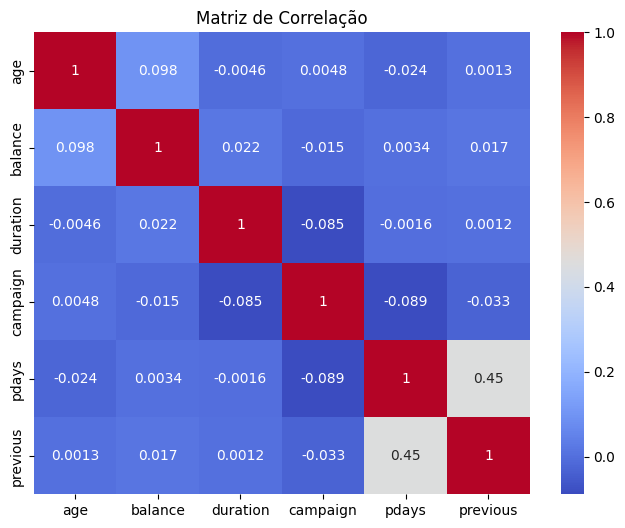

In [33]:
# Heatmap
correlation = df_clean[atributos_continuos].corr()
plt.figure(figsize=(8,6))
sns.heatmap(correlation, annot=True, cmap='coolwarm')
plt.title("Matriz de Correlação")
plt.show()

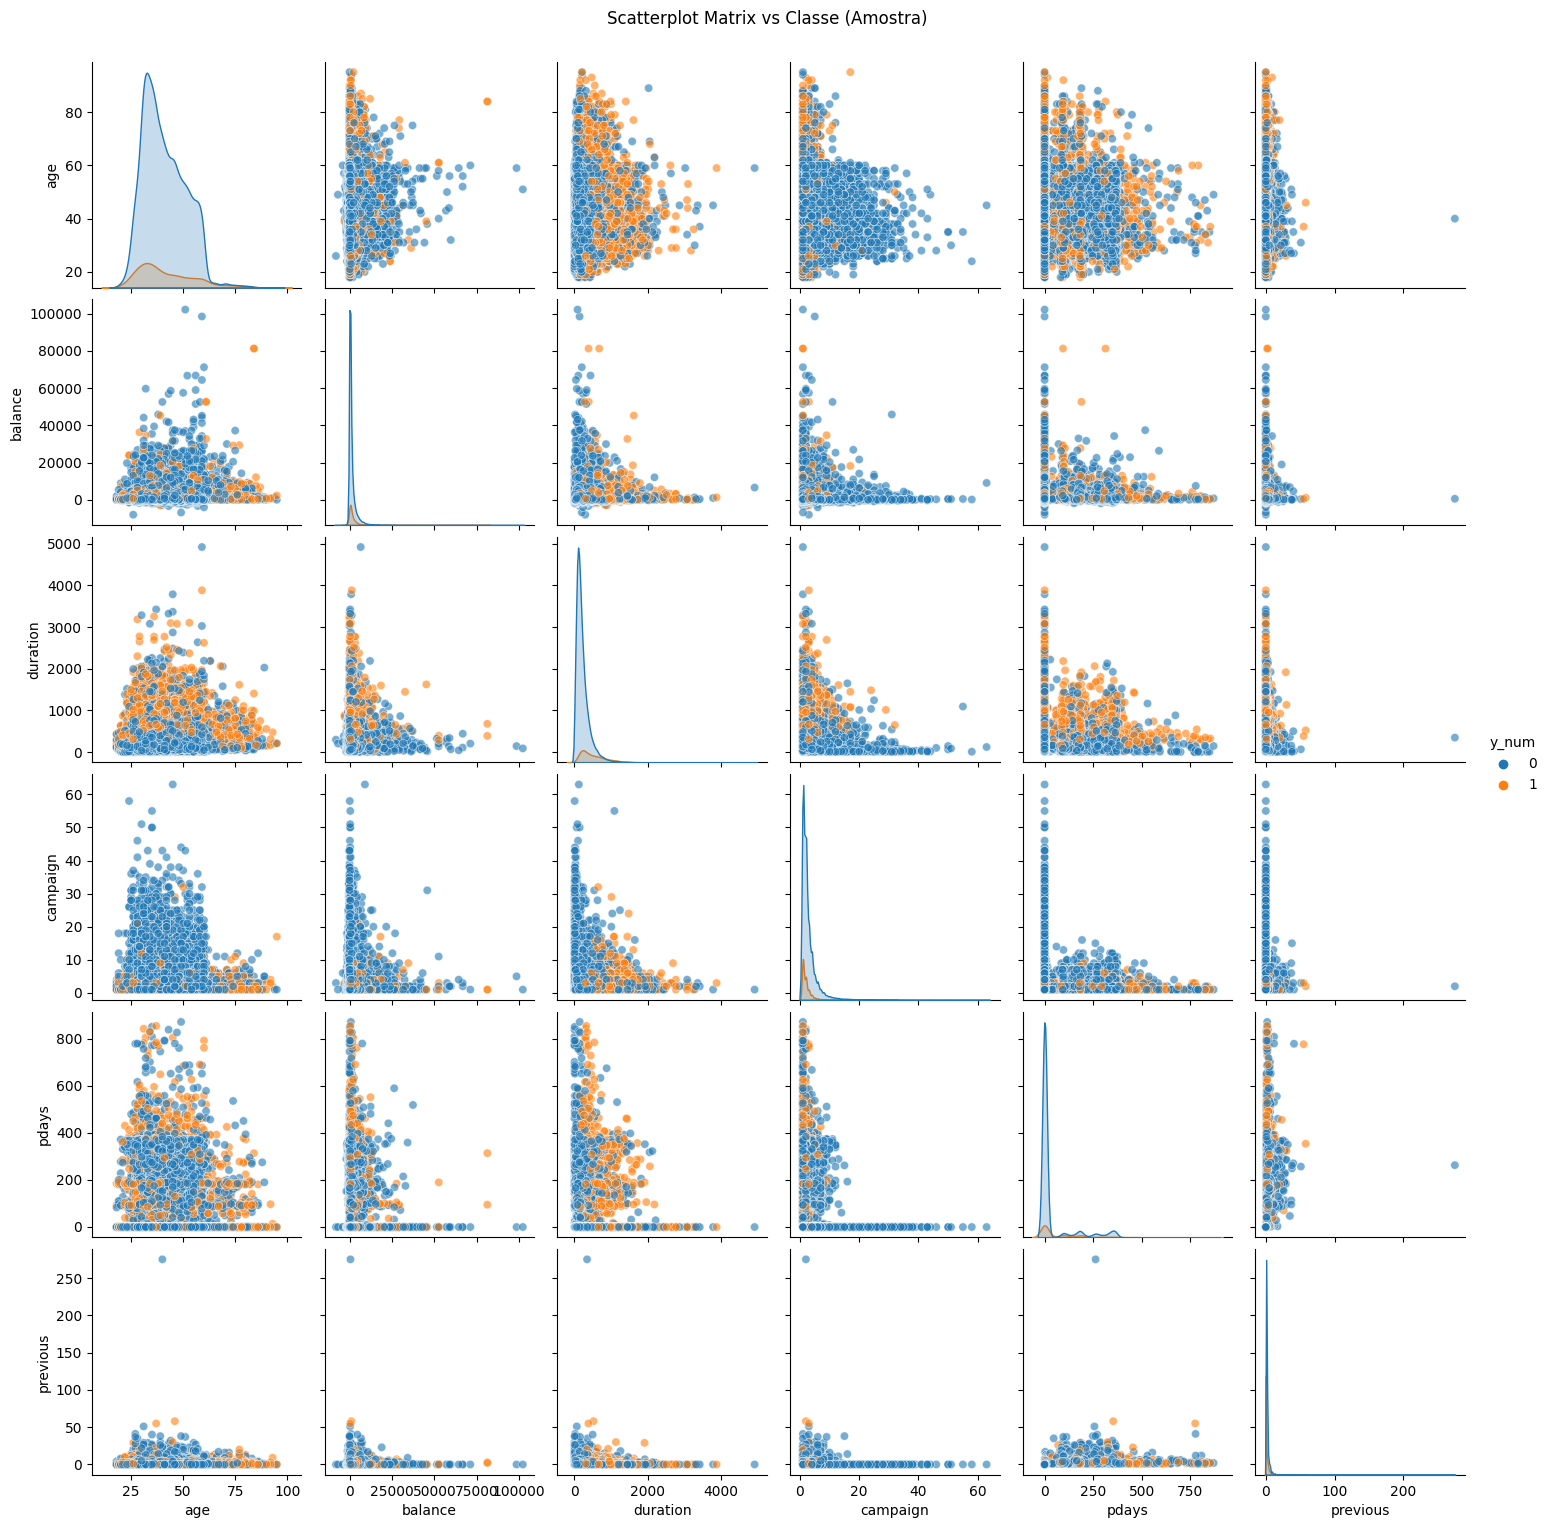

In [40]:
# Scatterplot
sample_size = 45000  # Ajusta o tamanho da amostra conforme necessário
df_sample = df_clean.sample(n=sample_size, random_state=42)

# Gerando o pairplot com a amostra
sns.pairplot(df_sample, vars=atributos_continuos, hue='y_num', plot_kws={"alpha": 0.6})
plt.suptitle("Scatterplot Matrix vs Classe (Amostra)", y=1.02)
plt.show()

In [41]:
# Selecionar apenas atributos numéricos contínuos e discretos (excluindo a classe 'y')
X = df_clean[atributos_continuos + atributos_discretos]
print(X.shape)

(45211, 7)


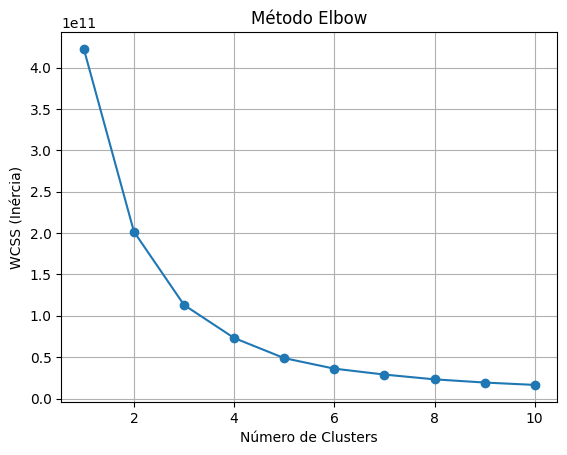

In [43]:
# Curva Elbow
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=0)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.title('Método Elbow')
plt.xlabel('Número de Clusters')
plt.ylabel('WCSS (Inércia)')
plt.grid(True)
plt.show()

Para n_clusters = 2, Silhouette média = 0.843


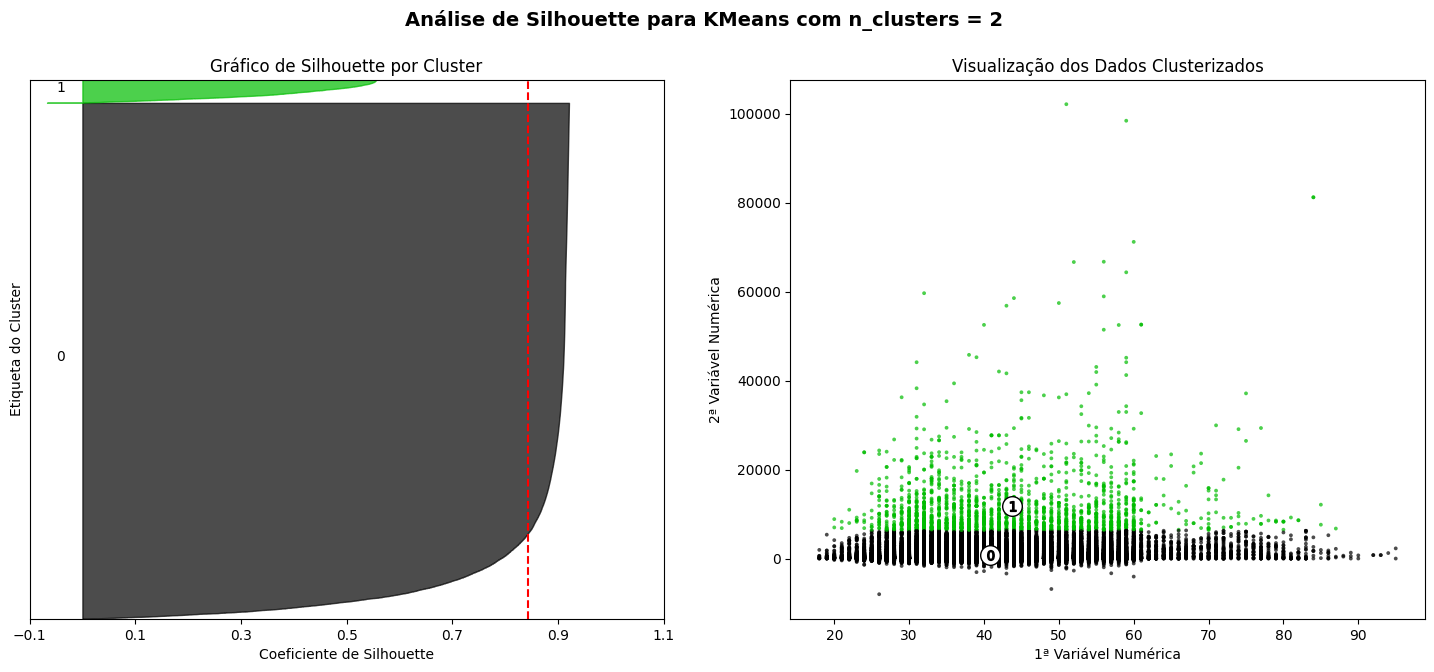

Para n_clusters = 3, Silhouette média = 0.771


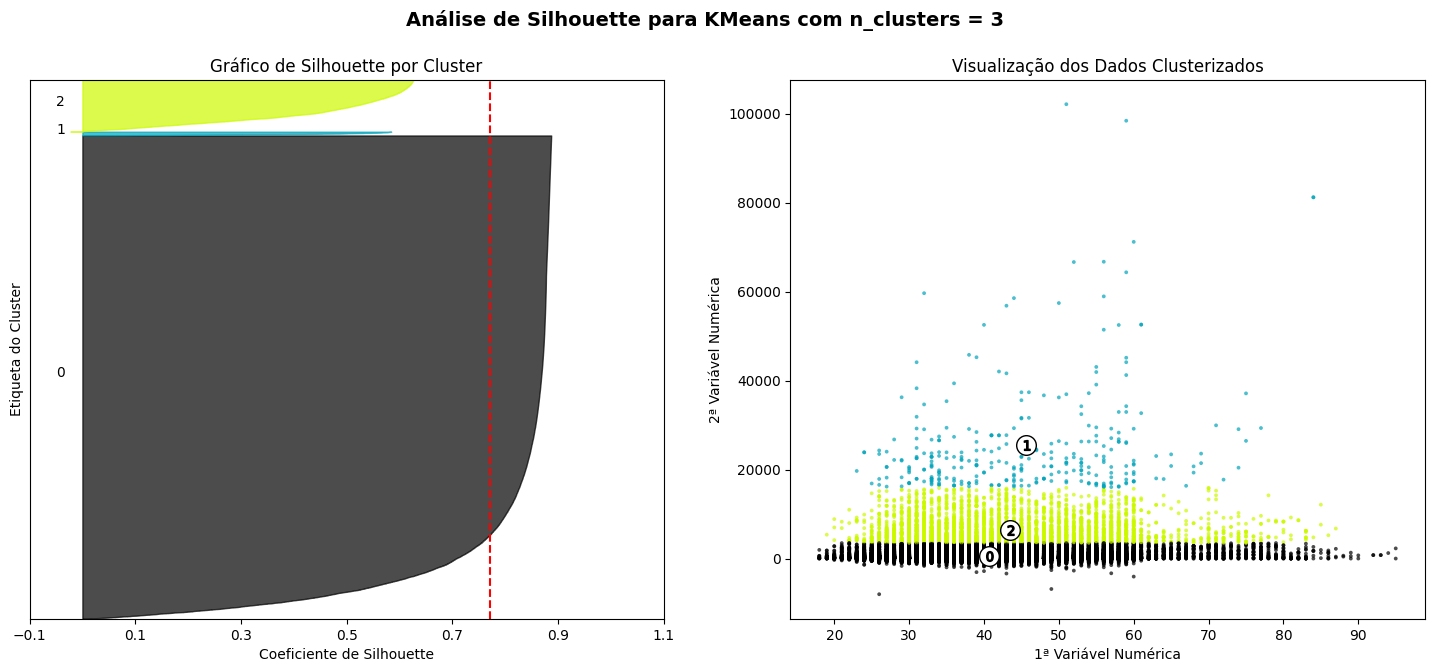

Para n_clusters = 4, Silhouette média = 0.733


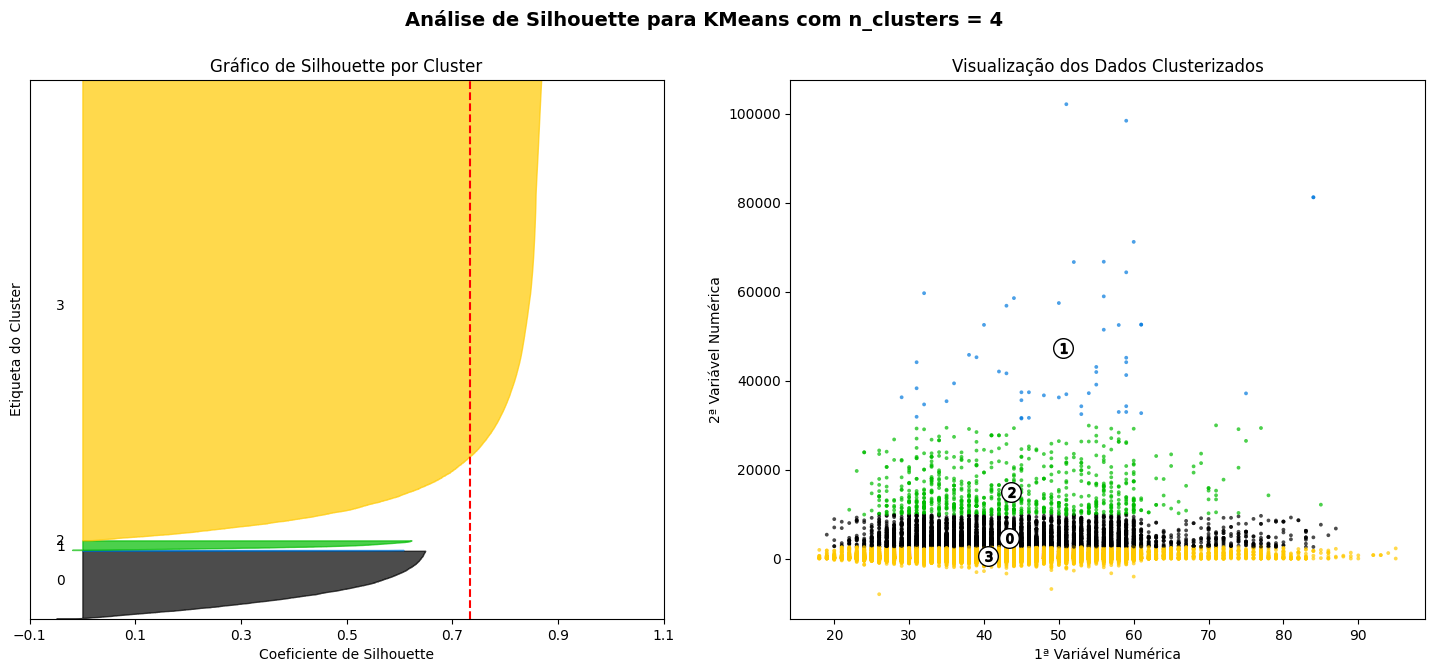

Para n_clusters = 5, Silhouette média = 0.685


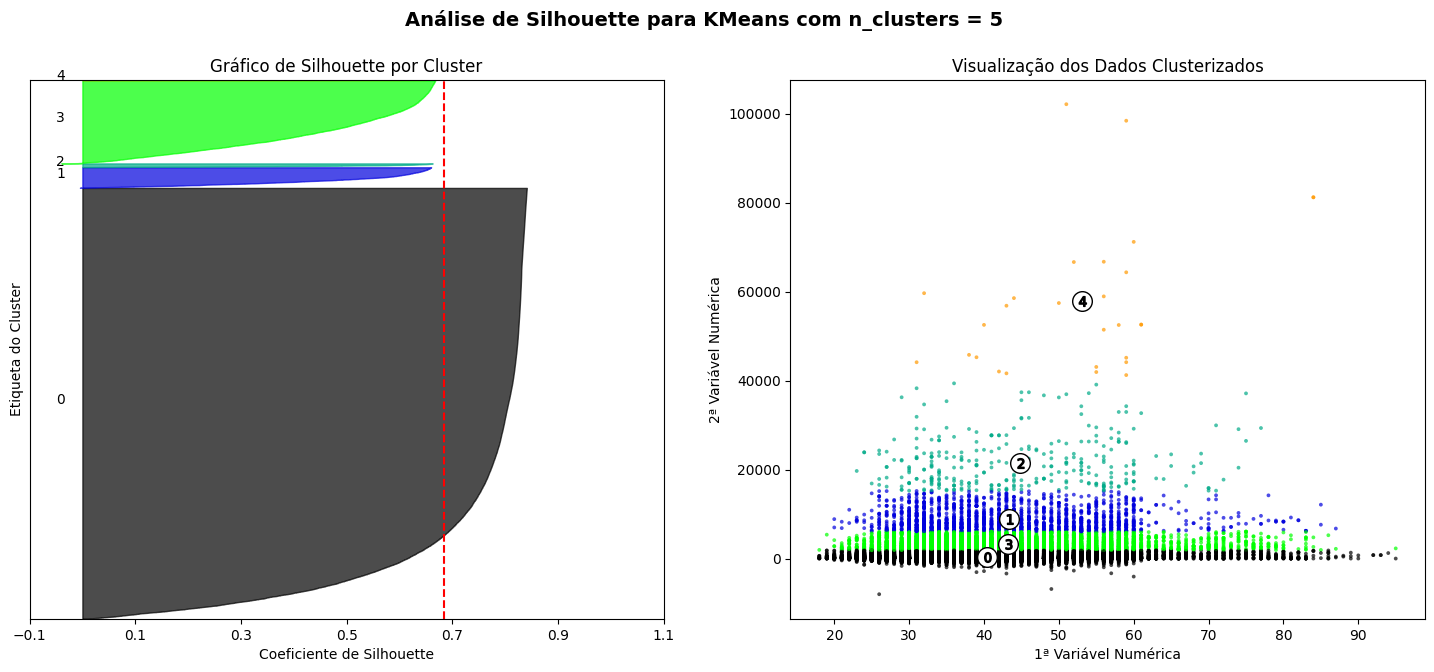

Para n_clusters = 6, Silhouette média = 0.630


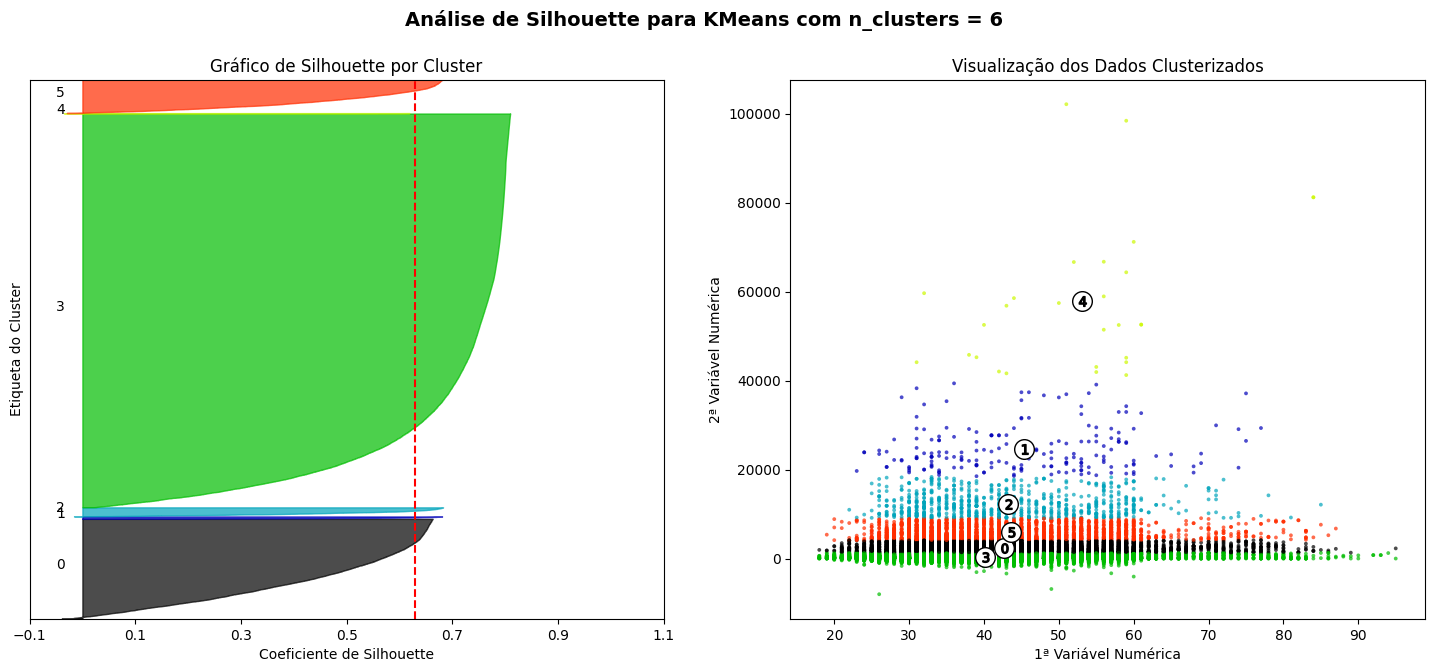

In [45]:
range_n_clusters = [2, 3, 4, 5, 6]

for n_clusters in range_n_clusters:
    fig, (ax1, ax2) = plt.subplots(1, 2)
    fig.set_size_inches(18, 7)

    ax1.set_xlim([-0.1, 1])
    ax1.set_ylim([0, len(X) + (n_clusters + 1) * 10])

    clusterer = KMeans(n_clusters=n_clusters, random_state=10)
    cluster_labels = clusterer.fit_predict(X)

    silhouette_avg = silhouette_score(X, cluster_labels)
    print(f"Para n_clusters = {n_clusters}, Silhouette média = {silhouette_avg:.3f}")

    sample_silhouette_values = silhouette_samples(X, cluster_labels)

    y_lower = 10
    for i in range(n_clusters):
        ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]
        ith_cluster_silhouette_values.sort()

        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i

        color = cm.nipy_spectral(float(i) / n_clusters)
        ax1.fill_betweenx(np.arange(y_lower, y_upper),
                          0, ith_cluster_silhouette_values,
                          facecolor=color, edgecolor=color, alpha=0.7)
        ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
        y_lower = y_upper + 10

    ax1.set_title("Gráfico de Silhouette por Cluster")
    ax1.set_xlabel("Coeficiente de Silhouette")
    ax1.set_ylabel("Etiqueta do Cluster")
    ax1.axvline(x=silhouette_avg, color="red", linestyle="--")
    ax1.set_yticks([])
    ax1.set_xticks(np.arange(-0.1, 1.1, 0.2))

    colors = cm.nipy_spectral(cluster_labels.astype(float) / n_clusters)
    ax2.scatter(X.iloc[:, 0], X.iloc[:, 1], marker='.', s=30, lw=0, alpha=0.7,
                c=colors, edgecolor='k')

    centers = clusterer.cluster_centers_
    ax2.scatter(centers[:, 0], centers[:, 1], c='white', s=200, edgecolor='k')
    for i, c in enumerate(centers):
        ax2.scatter(c[0], c[1], marker=f"${i}$", alpha=1, s=50, edgecolor='k')

    ax2.set_title("Visualização dos Dados Clusterizados")
    ax2.set_xlabel("1ª Variável Numérica")
    ax2.set_ylabel("2ª Variável Numérica")

    plt.suptitle(f"Análise de Silhouette para KMeans com n_clusters = {n_clusters}",
                 fontsize=14, fontweight='bold')
    plt.show()
